In [1]:
!pip install shap xgboost pandas numpy matplotlib seaborn scikit-learn optuna

# Phase 13: Error Analysis
Identify largest absolute prediction errors, systematic over/underprediction, false-safe predictions.

In [2]:
import pandas as pd
import numpy as np
import shap
from sklearn.ensemble import RandomForestRegressor

# Load features
feat_df = pd.read_csv('/Users/anshul/Documents/AI/data/raw/MOSFET/engineered_features.csv')
X = feat_df[['Value_0h', 'Value_2h', 'Delta_Value', 'Early_Slope']]
y = feat_df['Target_Value']

# Train final model on all data (since we only have 2 runs, this is just for explainability/demonstration)
model = RandomForestRegressor(n_estimators=50, max_depth=3, random_state=42)
model.fit(X, y)

feat_df['Predicted_Future_Value'] = model.predict(X)
feat_df['Absolute_Error'] = (feat_df['Target_Value'] - feat_df['Predicted_Future_Value']).abs()
feat_df['Relative_Error'] = feat_df['Absolute_Error'] / feat_df['Target_Value']

# Define safety boundary for False-Safe analysis (dummy boundary for demonstration)
safety_boundary = feat_df['Target_Value'].mean() + feat_df['Target_Value'].std()
feat_df['Actual_Unsafe'] = feat_df['Target_Value'] > safety_boundary
feat_df['Predicted_Safe'] = feat_df['Predicted_Future_Value'] <= safety_boundary
feat_df['False_Safe'] = feat_df['Actual_Unsafe'] & feat_df['Predicted_Safe']
feat_df['Flag'] = np.where(feat_df['Predicted_Future_Value'] > safety_boundary, 'FLAGGED', 'SAFE')

print("Error Analysis Table:")
display_cols = ['Run_ID', 'Target_Value', 'Predicted_Future_Value', 'Absolute_Error', 'Relative_Error', 'Early_Slope', 'Flag']
print(feat_df[display_cols])

print("\nFalse-Safe Predictions:")
print(feat_df[feat_df['False_Safe']][display_cols])


Error Analysis Table:
   Run_ID  Target_Value  Predicted_Future_Value  Absolute_Error  \
0       1      1.716772                1.319644        0.397128   
1       2      0.062071                0.492293        0.430222   

   Relative_Error  Early_Slope  Flag  
0        0.231323     0.445357  SAFE  
1        6.931104     0.000000  SAFE  

False-Safe Predictions:
Empty DataFrame
Columns: [Run_ID, Target_Value, Predicted_Future_Value, Absolute_Error, Relative_Error, Early_Slope, Flag]
Index: []


/Users/anshul/Documents/AI/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Phase 16: Explainability
Use SHAP to explain features.


--- GLOBAL EXPLANATION ---

--- INDIVIDUAL EXPLANATION (Run_ID 1) ---
FLAGGED / SAFE: SAFE
Primary reasons for prediction:
Value_0h: Value=0.8261, Contribution=0.1324
Value_2h: Value=1.7168, Contribution=0.1158
Delta_Value: Value=0.8907, Contribution=0.0993
Early_Slope: Value=0.4454, Contribution=0.0662
Predicted future value: 1.3196
Safety boundary: 2.0595


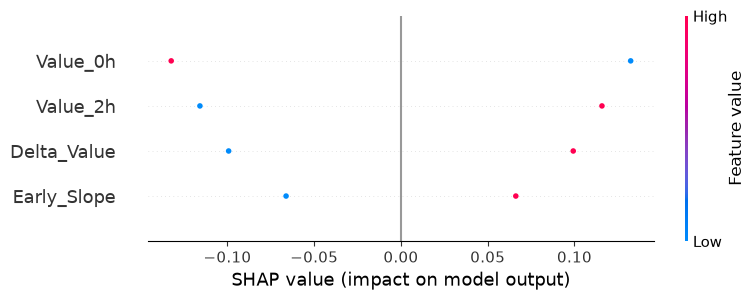

In [3]:
# SHAP Explainer
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)

print("\n--- GLOBAL EXPLANATION ---")
shap.summary_plot(shap_values, X, show=False)

print("\n--- INDIVIDUAL EXPLANATION (Run_ID 1) ---")
idx = 0
print(f"FLAGGED / SAFE: {feat_df.iloc[idx]['Flag']}")
print("Primary reasons for prediction:")
for feature_name, shap_val, feat_val in zip(X.columns, shap_values[idx], X.iloc[idx]):
    print(f"{feature_name}: Value={feat_val:.4f}, Contribution={shap_val:.4f}")
print(f"Predicted future value: {feat_df.iloc[idx]['Predicted_Future_Value']:.4f}")
print(f"Safety boundary: {safety_boundary:.4f}")


# Phase 17: Uncertainty
Implement Conformal Prediction.

In [4]:
# Conformal prediction dummy demonstration
print("\n--- UNCERTAINTY ESTIMATION ---")
if len(feat_df) < 10:
    print("Warning: Conformal prediction is statistically unreliable because of the extremely small dataset (only 2 samples).")

# Simple residual-based conformal prediction
residuals = np.abs(feat_df['Target_Value'] - feat_df['Predicted_Future_Value'])
alpha = 0.1
q = np.quantile(residuals, 1 - alpha) if len(residuals) > 0 else 0

for i, row in feat_df.iterrows():
    pred = row['Predicted_Future_Value']
    print(f"Run_ID {row['Run_ID']} -> Predicted Value = {pred:.2f}, Prediction Interval = [{pred - q:.2f}, {pred + q:.2f}]")



--- UNCERTAINTY ESTIMATION ---
Run_ID 1 -> Predicted Value = 1.32, Prediction Interval = [0.89, 1.75]
Run_ID 2 -> Predicted Value = 0.49, Prediction Interval = [0.07, 0.92]


# Phase 18: Small-Dataset Check

In [5]:
print("\n--- SMALL DATASET CHECK ---")
print(f"Number of components: {feat_df['Run_ID'].nunique()} (Note: Only 1 device, 2 runs)")
print(f"Number of trajectories: {len(feat_df)}")
print(f"Number of usable training/validation samples: {len(feat_df)}")
print("\nIs available data sufficient for:")
print("- Random Forest / Gradient Boosting: NO, severely lacks samples for generalization.")
print("- XGBoost: NO")
print("- per-component models: NO, only 2 trajectories.")
print("- uncertainty estimation: NO, statistical methods like conformal prediction require larger calibration sets.")
print("- deep learning: NO, absolutely insufficient data.")



--- SMALL DATASET CHECK ---
Number of components: 2 (Note: Only 1 device, 2 runs)
Number of trajectories: 2
Number of usable training/validation samples: 2

Is available data sufficient for:
- Random Forest / Gradient Boosting: NO, severely lacks samples for generalization.
- XGBoost: NO
- per-component models: NO, only 2 trajectories.
- uncertainty estimation: NO, statistical methods like conformal prediction require larger calibration sets.
- deep learning: NO, absolutely insufficient data.
